In [ ]:
%%html
<style>
table {display: inline-block}
td {text-align:left}
.consoleMachineFont {color:blue;font-family:Courier}
.consoleUserFont {font-family:Courier}
</style>

# קריאה וכתיבה מקבצים

### אג'נדה
- מבוא לקבצים
- פתיחה וסגירה של קבצים
- קריאה מקבצים
- כתיבה לקבצים

<span style="color: red;">TODO: סרטון מבוא לקבצים ותקיות.</span>

בחלק זה נלמד כיצד לעבוד עם קבצים בתוכניות פייתון, כלומר איך לקרוא מידע קיים ולכתוב מידע חדש אל מחוץ לקוד שלנו. שימוש בקבצים מאפשר לנו לשמור מידע בצורה **קבועה**, שאינה נעלמת עם סיום הריצה של התוכנית, להחזיק כמויות גדולות של נתונים, ולשתף מידע בין תוכניות שונות או בין מחשבים שונים.

נלמד כיצד לפתוח קובץ, לקרוא את תוכנו, לעדכן או להוסיף מידע ולשמור אותו מחדש. בסיום החלק הזה תוכלו לכתוב תוכניות ששומרות מידע טקסטאולי בקבצים במחשב שלכם. 



## מהו קובץ?

קובץ במחשב הוא משאב לאחסון מידע - אפשר לחשוב עליו כ"מסמך" דיגיטלי.
קבצים יכולים להכיל מידע מסוגים שונים - יש קבצי תמונה, מוזיקה, וידאו, טקסט, טבלאות ועוד.

לכל קובץ יש שם וסיומת (extension), שמרמזת על סוג התוכן שלו: `txt` לקובץ טקסט, `csv` לטבלת נתונים, `py` לקוד פייתון. בדף הזה נעבוד עם קבצי טקסט.

## איפה הקובץ נמצא?

כדי לפתוח קובץ מתוך הקוד צריך לומר לפייתון איפה הוא נמצא. המיקום של קובץ נקרא **ניתוב** (path), וכותבים אותו כמחרוזת.

- קובץ שנמצא באותה תיקייה שבה רץ הקוד נפתח לפי השם שלו בלבד.
- כשהקובץ נמצא בתוך תיקייה, כותבים את שם התיקייה, אחריו קו נטוי ואחריו את שם הקובץ.
- שתי נקודות פירושן לעלות תיקייה אחת למעלה.

```
data.txt
results/data.txt
../data.txt
```

ב-Google Colab הקוד רץ בתיקייה משלו. קובץ שהקוד שלכם יוצר נשמר בתיקייה הזו, ואפשר לראות אותו בחלונית הקבצים, שנפתחת בלחיצה על סמל התיקייה בצד המסך.

### תרגול
הניתובים שלמעלה הם **ניתובים יחסיים**: הם מתחילים מתיקייה מסוימת, למשל התיקייה שבה רץ הקוד. **ניתוב מלא**, לעומת זאת, מתחיל מהשורש של מערכת הקבצים, כלומר מהכונן עצמו.

בשאלה הבאה נתמקד בעץ התיקיות הבא:

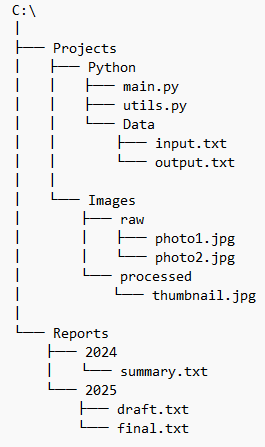

In [23]:
import json
from jupyterquiz import display_quiz

example = \
'''
[{
    "question": "מה הניתוב היחסי של הקובץ output כשמסתכלים מהקובץ input?",
    "type": "many_choice",
    "answers": [
        {
            "answer": "C:/Projects/Python/Data/output.txt",
            "correct": false,
            "feedback": "לא נכון"
        },
        {
            "answer": "C:/Projects/Python/Data",
            "correct": false,
            "feedback": "לא נכון"
        },
        {
            "answer": "output.txt",
            "correct": true,
            "feedback": "נכון!"
        },
        {
            "answer": "C:/Projects/Python/Data/output",
            "correct": false,
            "feedback": "לא נכון"
        }
    ]
}]
'''
myquiz = json.loads(example)
display_quiz(myquiz)


<IPython.core.display.Javascript object>

````{admonition} **להרחבה: ניתוב מלא, ניתוב יחסי וקו נטוי הפוך**
:class: dropdown, note

**ניתוב מלא** (absolute path) מתאר את הדרך אל הקובץ מהשורש של מערכת הקבצים. בעץ התיקיות שלמעלה, הניתוב המלא של הקובץ input הוא:

```
C:/Projects/Python/Data/input.txt
```

**ניתוב יחסי** (relative path) מתאר את הדרך אל הקובץ מהתיקייה שבה נמצא הקוד שרץ. אם הקוד נמצא בקובץ `main.py`, בתיקייה Python, אלה הניתובים היחסיים לקובץ input ולקובץ summary:

```
Data/input.txt
../../Reports/2024/summary.txt
```

בניתוב השני עולים פעמיים: מהתיקייה Python לתיקייה Projects, ומשם לשורש. נקודה אחת מסמנת את התיקייה הנוכחית, ולכן שני הניתובים הבאים שקולים:

```
./Data/input.txt
Data/input.txt
```

**קו נטוי הפוך.** במערכת ההפעלה Windows ניתובים נכתבים עם קו נטוי הפוך. במחרוזת בפייתון הקו הנטוי ההפוך שמור לתווים מיוחדים, כמו ירידת שורה, ולכן כותבים בניתוב קו נטוי רגיל, או שני קווים נטויים הפוכים ברצף:

```python
print('C:/Users/Desktop/file.txt')      # C:/Users/Desktop/file.txt
print('C:\\Users\\Desktop\\file.txt')   # C:\Users\Desktop\file.txt
```
````

## קבצי טקסט

קבצי טקסט מורכבים מ**שורות**.  כל שורה היא מחרוזת, כלומר **רצף תווים**.  
התו האחרון בכל שורה הוא התו המיוחד (escape character) ירידת שורה (‎`\n`‎).

**תזכורת:** רצף תווים (בד"כ 2) המתחילים בקו אלכסוני הפוך -`\` - נקראים גם **escape characters**, והם נועדו לסמן תווים שלא ניתן להקיש במקלדת באופן פשוט.   
בדרך כלל עורך טקסט לא מציג את התווים האלה עצמם, אלא את מה שהם מייצגים, למשל ירידת שורה.

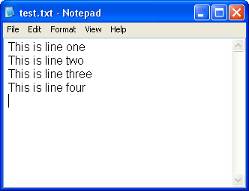

מאחורי הקלעים, התוכן של הקובץ הזה הוא רצף אחד של תווים:

```
This is line one\nThis is line two\nThis is line three\nThis is line four\n
```

## פתיחת וסגירת קבצים

### גישה לקובץ

כדי לגשת לקובץ בפייתון, משתמשים בפקודה `open`, שמקבלת שני פרמטרים:  
`filename` - מחרוזת המייצגת את הניתוב של הקובץ שמעוניינים לפתוח.  
‎`mode`‎ - מחרוזת שקובעת אילו פעולות מותר לבצע על הקובץ (מצבי הפתיחה מפורטים בהמשך).  

‎`open`‎ מחזירה אובייקט שמשמש **חיבור לקובץ**, ונקרא גם **handle**. בדוגמאות שבהמשך נשמור אותו במשתנה ‎`f`‎. ניתן לחשוב על ה-handle כ"צינור" שאפשר דרכו להעביר נתונים אל הקובץ וממנו. כלומר, **`f` אינו הקובץ עצמו, אלא משמש לתקשורת עם הקובץ**.  


#### מצבי פתיחת קובץ

- ‎`'r'`‎ - קריאה בלבד.
- ‎`'w'`‎ - כתיבה בלבד (ימחק את הנתונים הקודמים)
- ‎`'a'`‎ - הוספה לקובץ (כתיבה לסוף הקובץ הקיים)

**דוגמא לשימוש:** 
``` python
f = open("my_file.txt", "r")
```

In [9]:
import json
from jupyterquiz import display_quiz

example = \
'''
[{
    "question": "בדוגמא לעיל, האם יהיה ניתן לכתוב לתוך הקובץ my_file?",
    "type": "many_choice",
    "answers": [
        {
            "answer": "כן",
            "correct": false,
            "feedback": "לא נכון"
        },
        {
            "answer": "לא",
            "correct": true,
            "feedback": "נכון!"
        },
        {
            "answer": "רק להוסיף",
            "correct": false,
            "feedback": "לא נכון"
        }
    ]
}]
'''
myquiz = json.loads(example)
display_quiz(myquiz)


<IPython.core.display.Javascript object>

#### מה יקרה אם נפנה לקובץ שאינו קיים?

במצב קריאה (`r`) לא נוכל לפתוח קובץ שאינו קיים, ולכן נקבל שגיאה:

In [ ]:
f = open("not_existing_file.txt", "r")

לעומת זאת,  במצבי כתיבה (`w`) או הוספה (`a`), אם הקובץ אינו קיים, **יווצר קובץ חדש כל עוד הניתוב לספריה המכילה את הקובץ קיים** 

לדוגמה, הקוד הבא פותח במצב כתיבה קובץ שעדיין אינו קיים, וכך יוצר אותו. הוא כותב לקובץ שלוש שורות וסוגר אותו. נשתמש בקובץ הזה בהמשך הדף, ועל הכתיבה עצמה נרחיב בסופו.

In [ ]:
f = open("test_file_multi_line.txt", "w")
f.write("This is line1\nThis is line 2\nThe end")
f.close()

### סגירת קובץ

סגירה של קובץ מתבצעת על-ידי מתודה של אובייקט ה`file` שפתחנו. לדוגמה, אם שמרנו את האובייקט בשם f, נסגור את הקובץ על-ידי:
``` python
f.close()
```

חשוב לסגור כל קובץ שפתחנו: רק אחרי הסגירה מובטח שכל מה שכתבנו אכן נשמר בקובץ, והמשאבים שמערכת ההפעלה הקצתה לקובץ משתחררים.

### `with` context manager

כדי לא לקחת את הסיכון שנפתח קובץ ולא נסגור, ניתן להשתמש ב-`with` כדי להגדיר את הבלוק של הקוד, או את **הקונטקסט** בו קובץ יהיה זמין.  
הקובץ יפתח בתחילת הבלוק, **ויסגר אוטומטית** בסופו.

אם עד כה כתבנו כך:

In [ ]:
# replace this code:
f = open('test_file_multi_line.txt', 'r')
content = f.read()
f.close()

כעת, ניתן גם לכתוב כך.

In [ ]:
# with this:
with open('test_file_multi_line.txt', 'r') as f:
    content = f.read()
    
# close is automatically called afterwards

בשורה הראשונה הקובץ נפתח, והאובייקט שמייצג אותו נשמר בשם `f`.  
ברגע שהקוד יוצא מהבלוק של ה־`with` (כלומר נגמרת ההזחה), פייתון **סוגר את הקובץ אוטומטית**. פייתון יסגור את הקובץ אפילו אם בלוק הקוד לא סיים לרוץ בגלל שגיאה. 

כך אנחנו לא צריכים לזכור לקרוא ל־`close`, ולא לוקחים סיכון שהקובץ יישאר פתוח.

מכאן והלאה נפתח קבצים בעזרת `with`.

## קריאה מקובץ

לאחר שפתחנו את הקובץ (במצב קריאה) - ניתן להשתמש ב-handle שלנו (בדוגמאות למעלה `f`) כדי לקרוא את התוכן השמור בקובץ. כעת נראה שלוש דרכים נפוצות לקריאה מתוך קובץ.

### f.read

מתודה זו קוראת את כל תוכן הקובץ בבת אחת ומחזירה אותו כמחרוזת אחת ארוכה.

In [ ]:
with open('test_file_multi_line.txt', 'r') as f:
    content = f.read()

print(content)

בהדפסה כל שורה מופיעה בנפרד, כי כך פייתון מדפיסה את התו ‎`\n`‎. המחרוזת עצמה, ששמורה במשתנה `content`, היא רצף אחד של תווים:

```
'This is line1\nThis is line 2\nThe end'
```

### f.readlines

 מתודה זו קוראת את **כל השורות שנשארו בקובץ** ומחזירה אותן כ**רשימה של מחרוזות** (כל איבר ברשימה הוא שורה אחת).
מדובר בפקודה נוחה ביותר אם רוצים רשימה שאפשר לעבור עליה או לעבד אותה.

In [ ]:
with open('test_file_multi_line.txt', 'r') as f:
    lines = f.readlines()

print(lines)
print(lines[2])

```{admonition} **שימו לב**
:class: error

כל שורה ברשימה, מלבד האחרונה, מסתיימת בתו ‎`\n`‎.
```

### לולאת `for` על הקובץ

ניתן לעבור שורה-שורה באמצעות לולאת `for`. הדרך הזו מתאימה במיוחד לקבצים גדולים, מאחר שהיא לא שומרת בזכרון את כל הקובץ בבת אחת.

In [ ]:
with open('test_file_multi_line.txt', 'r') as f:
    for line in f:
        print(line, end='')   # each line already ends with \n, so print adds no second one

````{admonition} **להרחבה: קריאה של שורה אחת בכל פעם**
:class: dropdown, note

המתודה `readline` קוראת את השורה הבאה בקובץ ומחזירה אותה כמחרוזת. כל קריאה מתקדמת שורה אחת, ואי אפשר לחזור אחורה בלי לפתוח את הקובץ מחדש.

```python
with open('test_file_multi_line.txt', 'r') as f:
    line1 = f.readline()
    line2 = f.readline()

print(line1)   # This is line1, followed by an empty line
print(line2)   # This is line 2, followed by an empty line
```

השורה הריקה שמודפסת אחרי כל שורה נובעת מהתו ‎`\n`‎ שבסוף השורה שנקראה מהקובץ: הפונקציה `print` מוסיפה אחריו ירידת שורה משלה.
````

###  פונקציות שימושיות לעריכת מחרוזות בקבצים

כמו שראינו, כאשר אנחנו עובדים עם קבצים, אנחנו מקבלים טקסט גולמי.
הטקסט הזה לא תמיד מוכן לשימוש ישיר: לעיתים הוא כולל פסיקים, רווחים מיותרים, ירידות שורה או סימנים נוספים.
לכן חשוב להכיר כמה פונקציות בסיסיות שמאפשרות לנו לנקות, לפרק ולעבד מחרוזות, כדי שנוכל להפוך את המידע מהקובץ לנתונים שימושיים.

#### split - פירוק לתתי מחרוזות לפי תו מפריד

קבצים לעיתים מכילים טקסטים ארוכים, אפילו בשורה בודדת. באמצעות ‎`split()`‎ ניתן יהיה לפרק טקסט ארוך לפי תו מפריד. מתודה זו "תחתוך" את המחרוזת ממנה הופעלה המתודה בכל המקומות בהם יופיעו תווים מפרידים, ותחזיר רשימה המכילה כל תתי-המחרוזות שנוצרו בעקבות החיתוך. ברירת המחדל המחרוזת תפורק בכל תו רווח שהוא (‎`" ", \n, \t`‎ וכו').

לדוגמא, במקרה הזה נפצל את המחרוזת לפי פסיקים.

In [11]:
s = "topeka, kansas city,wichita,,olathe"

cities = s.split(',') 
# If a delimiter is not specified, the string is split to words separated by a sequence of whitespaces.

print(cities)

['topeka', ' kansas city', 'wichita', '', 'olathe']


ניתן לראות כי קיבלנו מחרוזת אחת ריקה, וזאת מאחר שיש שני פסיקים ביניהם "אין כלום" - כלומר יש ביניהם מחרוזת ריקה.

#### strip - ניקוי רווחים וירידות שורה

המתודה `strip` מחזירה מחרוזת חדשה, בלי הרווחים ותווי ירידת השורה שבתחילת המחרוזת ובסופה. היא לא מסירה תווים מאמצע המחרוזת.

In [18]:
'  \t\n spacious \t  '.strip()

'spacious'

כך מנקים את כל השורות ברשימה שהתקבלה מהמתודה `readlines`:

In [ ]:
lines = ['this is line 1\n', 'this is line 2\n', 'the end']
for i in range(len(lines)):
    lines[i] = lines[i].strip()
print(lines)

שורה שנקראה מקובץ היא תמיד מחרוזת, גם כשכתוב בה מספר. כדי לחשב איתה, ממירים אותה למספר בעזרת `float`:

In [ ]:
line = "36.6\n"
T = float(line.strip())
print(T + 1)

## כתיבה לקובץ

עד עכשיו למדנו רק כיצד ניתן לקרוא מקבצים. עכשיו נלמד לכתוב לקבצים בעצמנו.  
ראשית, נצטרך לפתוח את הקובץ בהרשאות כתיבה מתאימות (write/append). 
לאחר שהקובץ פתוח, ניתן להשתמש בפקודה ‎`f.write(string)`‎ כדי לכתוב לתוך הקובץ מחרוזת. חשוב לשים לב שהפקודה `write` כותבת בדיוק את התוכן שנעביר לה, כולל רווחים ותווי ירידת שורה אם הוספנו כאלו.

בואו נראה דוגמה. נפתח את הקובץ `test_file_3.txt` במצב כתיבה ונבצע שתי פקודות `write`, שנכתבות לקובץ אחת אחרי השנייה. הפקודה `write` מקבלת רק מחרוזת, ולכן מספר צריך להמיר למחרוזת לפני הכתיבה, בעזרת `str` או בעזרת f-string.

In [ ]:
T = 36.6

with open('test_file_3.txt', 'w') as f:
    f.write("This is a test\n")
    f.write(f"T = {T:.1f}\n")

כעת נפתח את הקובץ במצב קריאה, ונראה מה כתבנו אליו:

In [ ]:
with open('test_file_3.txt', 'r') as f:
    print(f.read())

```{admonition} **רמז**
:class: tip

שימו לב שירידת השורה אשר מופיעה בקובץ נובעת מכך שכתבנו ‎`\n`‎. היא לא מתבצעת באופן אוטומטי

```



#### דוגמא: כתיבת רשימת מספרים לקובץ טקסט

בדוגמה זו נרצה לכתוב לתוך קובץ רשימה של המספרים הריבועיים של המספרים 1-10, כל אחד בשורה נפרדת.
ראשית, ניצור רשימה של המספרים אותם אנחנו רוצים לרשום. נבצע זאת באמצעות **list comprehension**.

In [ ]:
my_list = [i**2 for i in range(1,11)] 


כעת נכתוב את המספרים לקובץ בשם `output.txt`. עבור כל מספר ברשימה נבצע פקודת `write`, שכותבת לקובץ את המספר ואחריו תו ירידת שורה:

In [ ]:
with open("output.txt", "w") as f:
    for item in my_list:
        f.write(f"{item}\n")

כעת נוכל לקרוא מהקובץ ולראות מה כתבנו.

In [ ]:
# now let's view the output file
with open('output.txt', 'r') as f:
    print(f.read())

## תרגול: טמפרטורות בקובץ

הקוד הבא יוצר קובץ בשם `temps.txt`, ובו הטמפרטורות של כמה גופים, טמפרטורה אחת בכל שורה:

In [ ]:
temps = [80.0, 50.0, 35.0]

with open("temps.txt", "w") as f:
    for T in temps:
        f.write(f"{T:.1f}\n")

1. ממשו את הפונקציה `read_temps`, שמקבלת ניתוב לקובץ כזה ומחזירה רשימה של הטמפרטורות שבו, כמספרים מסוג `float`.
2. קראו את הטמפרטורות מהקובץ, קררו אותן צעד אחד עם ‎`k = 0.5`‎ בעזרת הפונקציה `cooled`, וכתבו את התוצאות לקובץ חדש בשם `cooled.txt`: טמפרטורה אחת בכל שורה, עם ספרה אחת אחרי הנקודה העשרונית.

In [ ]:
def cool(T, k, T_room=20.0):
    return T - k * (T - T_room)


def cooled(temps, k):
    new = []
    for T in temps:
        new.append(cool(T, k))
    return new


def read_temps(path):
    # delete pass and fill in your code below
    pass


print(read_temps("temps.txt") == [80.0, 50.0, 35.0])

# Write your code for part 2 here

````{admonition} **לחצו כאן כדי לצפות בפתרון**
:class: dropdown, tip

```python
def read_temps(path):
    temps = []
    with open(path, "r") as f:
        for line in f:
            temps.append(float(line.strip()))
    return temps


temps = read_temps("temps.txt")
print(temps)   # [80.0, 50.0, 35.0]

with open("cooled.txt", "w") as f:
    for T in cooled(temps, 0.5):
        f.write(f"{T:.1f}\n")
```

כל שורה שנקראת מקובץ היא מחרוזת, ולכן ממירים אותה למספר בעזרת `float` לפני שמחשבים איתה. אחרי ההרצה, בקובץ `cooled.txt` יופיעו השורות:

```
50.0
35.0
27.5
```
````